In [135]:
import numpy as np
import pandas as pd

from wm.env.paths import MPC_LOG

# success thresholds, fixed before looking at results
SUCCESS_DIST = 2.0  # px from target
SUCCESS_SPEED = 1.0  # px/step
Z = 1.96  # 95% normal interval; fine at n=50

results = pd.read_json(MPC_LOG, lines=True)
RUN_ID = results["run_id"].dropna().iloc[-1]  # latest sweep; set by hand to inspect another
run = results[results["run_id"] == RUN_ID]
print(RUN_ID, run.groupby("planner")["seed"].nunique().to_dict())

20261113-104517 {'model': 50, 'oracle': 50}


In [136]:
def ci(x: pd.Series) -> pd.Series:
    """Mean and 95% half-width across seeds (ddof=1)."""
    return pd.Series({"mean": x.mean(), "ci95": Z * x.std() / np.sqrt(len(x)), "n": len(x)})


def paired(wide: pd.DataFrame) -> pd.Series:
    """Model minus oracle per seed: both planners share targets and candidates."""
    return ci(wide["model"] - wide["oracle"])

In [137]:
# step 50 is the final row: the state after the last action
finals = run[run["step"] == 50].set_index(["seed", "planner"])
final_dist = finals["dist"].unstack("planner")
final_speed = finals["speed"].unstack("planner")

display(
    final_dist.apply(ci).T.assign(
        std=final_dist.std(), median=final_dist.median(), max=final_dist.max()
    )
)
display(paired(final_dist).rename("model - oracle"))

,mean,ci95,n,std,median,max
planner,,,,,,
model,0.969435,0.193016,50.0,0.696341,0.920688,4.298055
oracle,0.306143,0.046941,50.0,0.169348,0.304529,0.781476


mean     0.663292
ci95     0.202042
n       50.000000
Name: model - oracle, dtype: float64

In [138]:
near = final_dist < SUCCESS_DIST
stopped = final_speed < SUCCESS_SPEED
display(
    pd.DataFrame(
        {
            f"dist < {SUCCESS_DIST}": near.mean(),
            f"+ speed < {SUCCESS_SPEED}": (near & stopped).mean(),
            "final speed": final_speed.mean(),
        }
    )
)

,dist < 2.0,+ speed < 1.0,final speed
planner,,,
model,0.96,0.84,0.613029
oracle,1.00,1.00,0.433344


In [139]:
# last 20 states (steps 31-50): average each seed first, then spread across seeds
last_20 = (
    run[run["step"].between(31, 50)].groupby(["seed", "planner"])["dist"].mean().unstack("planner")
)
display(last_20.apply(ci).T)
display(paired(last_20).rename("model - oracle"))

,mean,ci95,n
planner,,,
model,0.916484,0.160334,50.0
oracle,0.353931,0.014815,50.0


mean     0.562553
ci95     0.154729
n       50.000000
Name: model - oracle, dtype: float64

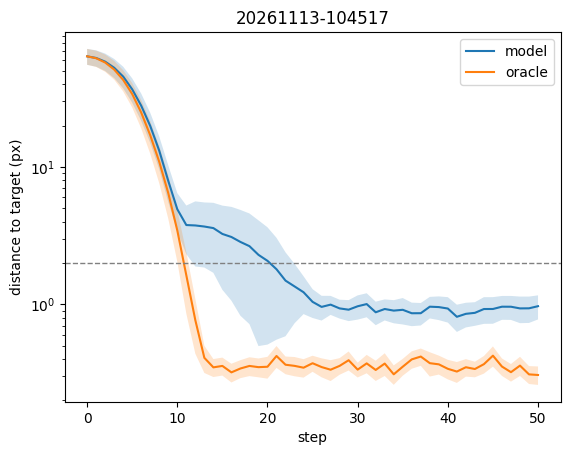

In [140]:
# distance over time: mean across seeds with a 95% band
by_step = run.groupby(["planner", "step"])["dist"].agg(["mean", "std", "count"])
by_step["ci95"] = Z * by_step["std"] / np.sqrt(by_step["count"])
ax = None
for planner, d in by_step.groupby(level="planner"):
    d = d.droplevel("planner")
    ax = d["mean"].plot(ax=ax, label=planner, logy=True)
    ax.fill_between(d.index, d["mean"] - d["ci95"], d["mean"] + d["ci95"], alpha=0.2)
ax.axhline(SUCCESS_DIST, color="grey", ls="--", lw=1)
ax.set(xlabel="step", ylabel="distance to target (px)", title=RUN_ID)
ax.legend();

In [141]:
# CEM vs random shooting: same cost (latent L2), same budget (512 evaluations per step),
# paired per seed. The baseline must use the same loss_type as the CEM run.
RUNS = {"random": "20261111-133532", "cem": "20261112-192152"}
cmp = results[results["run_id"].isin(RUNS.values())].assign(
    search=lambda d: d["run_id"].map({v: k for k, v in RUNS.items()})
)
print(cmp.groupby("search")[["loss_type", "run_id"]].first())

cmp_final = cmp[cmp["step"] == 50].pivot_table(
    index=["planner", "seed"], columns="search", values="dist"
)
cmp_last20 = cmp[cmp["step"].between(31, 50)].pivot_table(
    index=["planner", "seed"], columns="search", values="dist", aggfunc="mean"
)


def cmp_table(wide: pd.DataFrame) -> pd.DataFrame:
    """Mean per search, and the paired cem - random difference with its 95% CI and median."""
    diff = (wide["cem"] - wide["random"]).groupby(level="planner")
    return pd.DataFrame(
        {
            "random": wide["random"].groupby(level="planner").mean(),
            "cem": wide["cem"].groupby(level="planner").mean(),
            "cem - random": diff.mean(),
            "ci95": Z * diff.std() / np.sqrt(diff.count()),
            "median diff": diff.median(),
        }
    )


display(cmp_table(cmp_final).rename_axis("final dist"))
display(cmp_table(cmp_last20).rename_axis("last-20 dist"))

       loss_type           run_id
search                           
cem           l2  20261112-192152
random        l2  20261111-133532


,random,cem,cem - random,ci95,median diff
final dist,,,,,
model,1.425238,2.195228,0.769990,2.468506,-0.456272
oracle,0.897155,0.419429,-0.477726,0.153477,-0.430641


,random,cem,cem - random,ci95,median diff
last-20 dist,,,,,
model,1.435645,1.974228,0.538583,1.976541,-0.485237
oracle,0.892739,0.473273,-0.419465,0.044657,-0.403341


In [142]:
# Runaways: a stronger optimiser can find plans the model wrongly likes. Speed alone is not
# a marker (covering ~100 px fast often passes the data's p99 of 12.9 px/step), so flag
# episodes that end far from the target, and show their peak speed.
RUNAWAY_DIST = 10.0  # px at step 50
max_speed = cmp.groupby(["search", "planner", "seed"])["speed"].max()
final_by = cmp[cmp["step"] == 50].set_index(["search", "planner", "seed"])["dist"]
speed_table = pd.DataFrame({"max speed": max_speed, "final dist": final_by})
display(speed_table[speed_table["final dist"] > RUNAWAY_DIST].round(2))

# the same comparison without seeds that ran away under either search
bad = (speed_table["final dist"] > RUNAWAY_DIST).groupby(level=["planner", "seed"]).any()
display(cmp_table(cmp_last20[~bad.reindex(cmp_last20.index)]).rename_axis("last-20, no runaways"))

,,,max speed,final dist
search,planner,seed,,
cem,model,8,26.93,63.38


,random,cem,cem - random,ci95,median diff
"last-20, no runaways",,,,,
model,1.438492,0.969834,-0.468658,0.098305,-0.486692
oracle,0.892739,0.473273,-0.419465,0.044657,-0.403341


In [143]:
# CEM convergence: does the search settle within CEM_ITERS iterations?
# Fresh situations set up as mpc() does, cold start (no warm start, the hardest case),
# run to MAX_ITERS and score the mean plan after every iteration with the simulator.
# Two regimes: far (episode start) and near the target (the hover phase).
import random

import torch

import wm.env.sim as sim
import wm.plan.mpc as M
from wm.env.paths import LATEST_RUN
from wm.plan.cem import CEM_ITERS, cem
from wm.probe.runner import load_run

model_run = load_run(LATEST_RUN)
model_run.nets.eval()
dev = model_run.device
N_SITUATIONS, MAX_ITERS = 20, 12
INIT_STD = 0.5  # as the headline CEM sweep (run 20261113-104517)


def situation(seed: int, near: bool):
    """Current state, frame pair, target and goal latent, as mpc() sets them up."""
    rng = random.Random(seed)
    g = torch.Generator(device=dev).manual_seed(seed)
    target = M.generate_target(dev, g)
    if near:  # a few px from the target, slow
        tx, ty = target.tolist()
        x0, x1, y0, y1 = M.center_bounds()
        s0 = np.array(
            [
                np.clip(tx + rng.uniform(-3, 3), x0, x1),
                np.clip(ty + rng.uniform(-3, 3), y0, y1),
                rng.uniform(-1, 1),
                rng.uniform(-1, 1),
            ]
        )
    else:
        s0 = np.asarray(sim.reset(rng), dtype=np.float64)
    s1 = np.asarray(sim.step(s0, sim.random_action(rng)), dtype=np.float64)
    with torch.no_grad():
        goal = M.frame_tensor(target)
        zt = M.encode_pair(model_run.nets.encoder_target, goal, goal, dev)
    return s1, M.frame_tensor(s0), M.frame_tensor(s1), target, zt, g


rows = []
for seed in range(N_SITUATIONS):
    for near in (False, True):
        state, fp, fn, target, zt, g = situation(seed, near)
        cost_fns = {
            "model": lambda a: M.model_costs(model_run, fp, fn, a, zt, "l2")[0],
            "oracle": lambda a: M.sim_costs(state, a, target)[0],
        }
        for planner, cost_fn in cost_fns.items():
            hist = []
            cem(
                cost_fn,
                torch.zeros(M.H, 2, device=dev),
                g,
                n_iters=MAX_ITERS,
                init_std=INIT_STD,
                history=hist,
            )
            plans = torch.stack([h["means"] for h in hist])  # (iters, H, 2)
            true = M.sim_costs(state, plans, target)[0].cpu().numpy()  # sim cost of each mean
            for h, t in zip(hist, true):
                rows.append(
                    {
                        "seed": seed,
                        "regime": "near" if near else "far",
                        "planner": planner,
                        "iter": h["iter"],
                        "own_elite": h["elite_cost"],
                        "std": h["std"],
                        "true_of_mean": float(t),
                    }
                )
conv = pd.DataFrame(rows)
# own costs are in different units per planner, so show them relative to iteration 1
conv["own_elite_rel"] = conv["own_elite"] / conv.groupby(["seed", "regime", "planner"])[
    "own_elite"
].transform("first")

sim cost @ 4  sim cost @ 12  still to gain  ci95
regime planner                                                  
far    model           47.32          45.42           1.91  0.69
       oracle          45.39          43.02           2.36  0.67
near   model            2.76           2.67           0.09  0.12
       oracle           1.33           0.91           0.42  0.12

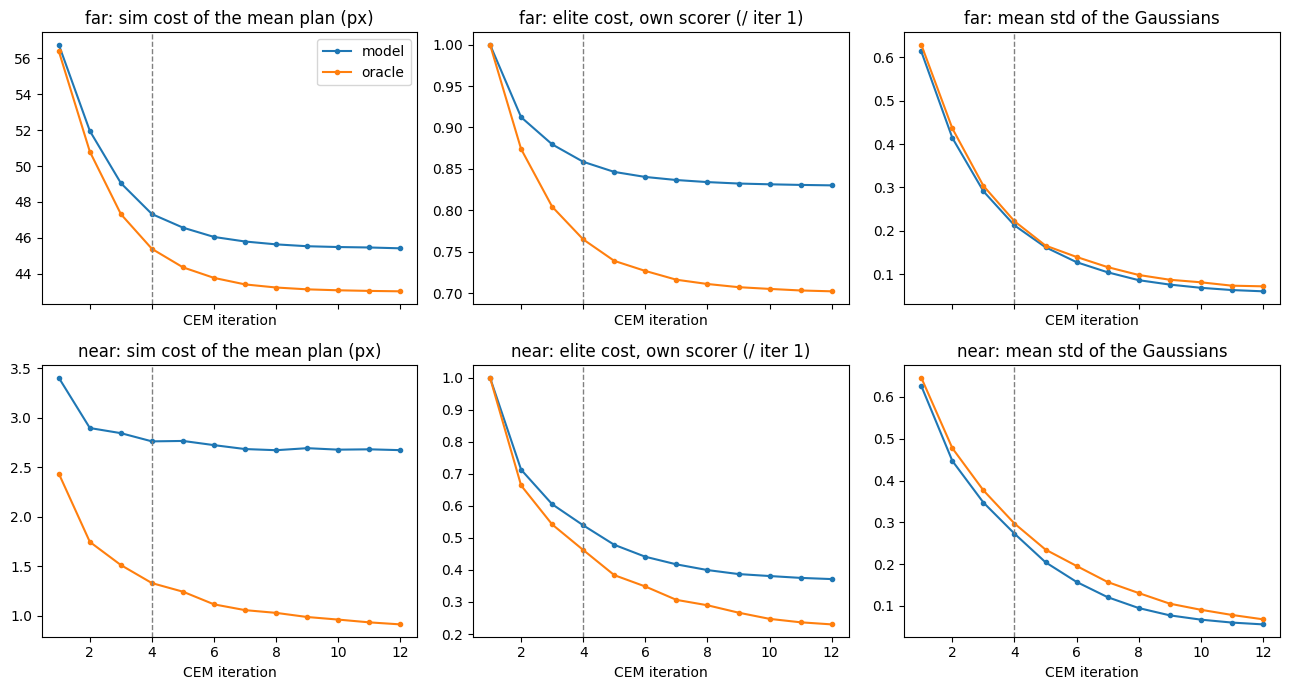

In [144]:
import matplotlib.pyplot as plt

panels = [
    ("true_of_mean", "sim cost of the mean plan (px)"),
    ("own_elite_rel", "elite cost, own scorer (/ iter 1)"),
    ("std", "mean std of the Gaussians"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for r, regime in enumerate(["far", "near"]):
    for c, (col, label) in enumerate(panels):
        ax = axes[r, c]
        for planner, d in conv[conv["regime"] == regime].groupby("planner"):
            m = d.groupby("iter")[col].mean()
            ax.plot(m.index, m.values, marker="o", ms=3, label=planner)
        ax.axvline(CEM_ITERS, color="grey", ls="--", lw=1)
        ax.set(title=f"{regime}: {label}", xlabel="CEM iteration")
axes[0, 0].legend()
fig.tight_layout()

# what is left on the table at CEM_ITERS: sim cost of the mean at CEM_ITERS minus at MAX_ITERS
at = conv[conv["iter"].isin([CEM_ITERS, MAX_ITERS])].pivot_table(
    index=["regime", "planner", "seed"], columns="iter", values="true_of_mean"
)
gain = (at[CEM_ITERS] - at[MAX_ITERS]).groupby(level=["regime", "planner"])
display(
    pd.DataFrame(
        {
            f"sim cost @ {CEM_ITERS}": at[CEM_ITERS].groupby(level=["regime", "planner"]).mean(),
            f"sim cost @ {MAX_ITERS}": at[MAX_ITERS].groupby(level=["regime", "planner"]).mean(),
            "still to gain": gain.mean(),
            "ci95": Z * gain.std() / np.sqrt(gain.count()),
        }
    ).round(2)
)